In [1]:

import pandas as pd

df = pd.read_csv("ats_clustering_ready.csv")

print("Dataset size:", df.shape)

df.head()


Dataset size: (7043, 13)


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,InternetService_DSL,InternetService_Fiber_optic,Contract_Month_to_month,Contract_One_year,Contract_Two_year,Churn
0,0,0,0,-1.277445,0,0,-1.321350,1,0,1,0,0,1
1,1,0,0,0.351370,1,0,-1.321350,1,0,0,1,0,0
2,0,0,1,0.799294,1,0,-1.520755,1,0,1,0,0,0
3,0,0,0,-1.277445,1,0,0.373593,1,0,0,1,0,1
4,1,0,0,1.410099,1,0,-0.457261,0,1,1,0,0,0


In [2]:

# Select the two features required by ACS
X = df[["tenure", "MonthlyCharges"]]

# Display the first five rows
print(X.head())

# Check for missing values
print("\nMissing values:")
print(X.isnull().sum())


     tenure  MonthlyCharges
0 -1.277445       -1.321350
1  0.351370       -1.321350
2  0.799294       -1.520755
3 -1.277445        0.373593
4  1.410099       -0.457261

Missing values:
tenure            0
MonthlyCharges    0
dtype: int64


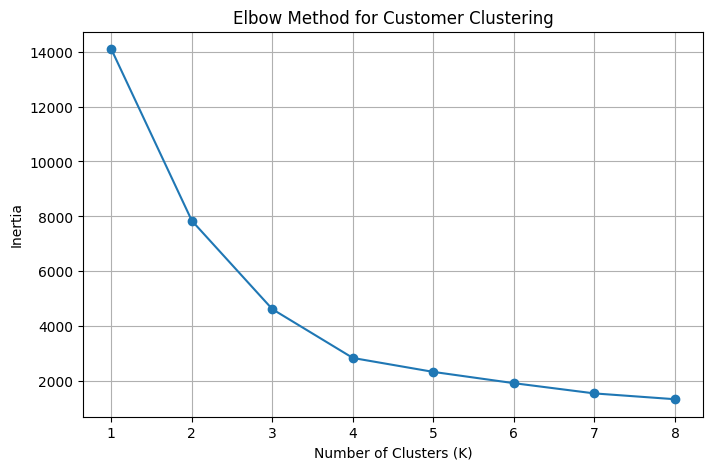

In [3]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store the results for different cluster numbers
inertia = []

# Test cluster numbers from 1 to 8
for k in range(1, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    inertia.append(model.inertia_)

# Draw the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Clustering")
plt.grid(True)

plt.show()


In [4]:

# Create the K-Means clustering model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the model and assign customers to clusters
df["Cluster"] = kmeans.fit_predict(X)

# Display the number of customers in each cluster
print("Customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())


Customers in each cluster:
Cluster
0    2202
1    1733
2    1948
3    1160
Name: count, dtype: int64


In [5]:

# Calculate the average features for each cluster
cluster_summary = df.groupby("Cluster")[
    ["tenure", "MonthlyCharges"]
].mean()

# Add the number of customers
cluster_summary["Customers"] = (
    df.groupby("Cluster").size()
)

# Display the summary
print(cluster_summary.round(2))


         tenure  MonthlyCharges  Customers
Cluster                                   
0         -0.72            0.55       2202
1         -0.89           -1.07       1733
2          1.07            0.94       1948
3          0.88           -1.02       1160


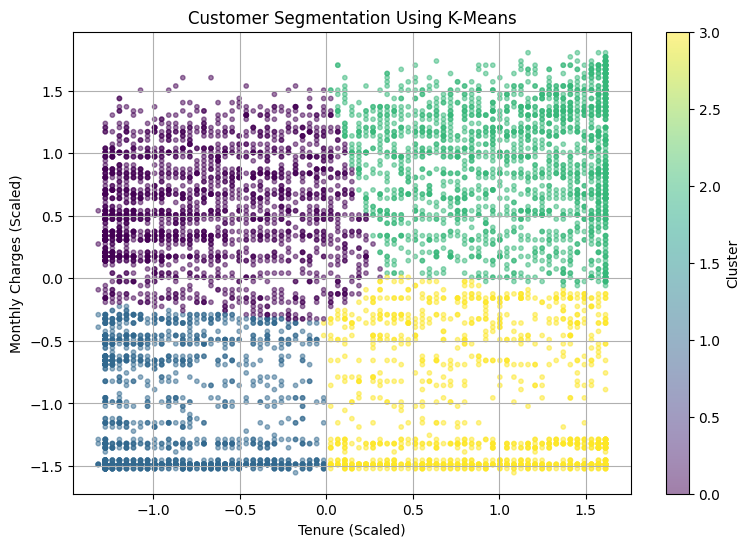

In [6]:

# Visualise the four customer clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    df["tenure"],
    df["MonthlyCharges"],
    c=df["Cluster"],
    cmap="viridis",
    s=10,
    alpha=0.5
)

plt.xlabel("Tenure (Scaled)")
plt.ylabel("Monthly Charges (Scaled)")
plt.title("Customer Segmentation Using K-Means")

plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()


In [7]:

# Read the scaling information from Harjot
scaler_info = pd.read_csv("scaler_params.csv")

# Display the information
print(scaler_info.to_string(index=False))


    Unnamed: 0    mean     std
        tenure 32.3105 24.5833
MonthlyCharges 64.5901 30.1506


In [8]:

# Read the scaler parameters correctly
scaler = pd.read_csv(
    "scaler_params.csv",
    index_col=0
)

# Convert tenure into actual months
df["Tenure_Months"] = (
    df["tenure"] * scaler.loc["tenure", "std"]
    + scaler.loc["tenure", "mean"]
)

# Convert monthly charges into actual dollars
df["Monthly_Charges_AUD"] = (
    df["MonthlyCharges"] * scaler.loc["MonthlyCharges", "std"]
    + scaler.loc["MonthlyCharges", "mean"]
)

# Show the average values for each cluster
cluster_actual = df.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Average_Tenure=("Tenure_Months", "mean"),
    Average_Monthly_Charges=("Monthly_Charges_AUD", "mean")
)

print(cluster_actual.round(2))


         Customers  Average_Tenure  Average_Monthly_Charges
Cluster                                                    
0             2202           14.73                    81.10
1             1733           10.39                    32.25
2             1948           58.73                    92.96
3             1160           54.06                    33.92


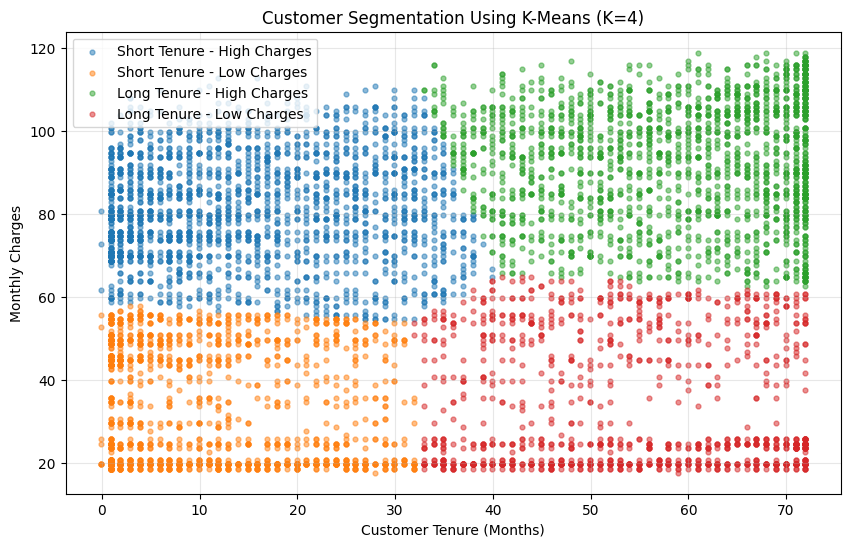

In [9]:

# Give each customer cluster a meaningful label
cluster_names = {
    0: "Short Tenure - High Charges",
    1: "Short Tenure - Low Charges",
    2: "Long Tenure - High Charges",
    3: "Long Tenure - Low Charges"
}

plt.figure(figsize=(10, 6))

# Plot each cluster separately
for cluster in range(4):
    group = df[df["Cluster"] == cluster]

    plt.scatter(
        group["Tenure_Months"],
        group["Monthly_Charges_AUD"],
        label=cluster_names[cluster],
        s=12,
        alpha=0.5
    )

plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.title("Customer Segmentation Using K-Means (K=4)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig("customer_segments.png", dpi=300, bbox_inches="tight")
plt.show()


In [10]:

# Calculate churn rate for each customer cluster
churn_summary = df.groupby("Cluster").agg(
    Total_Customers=("Churn", "count"),
    Customers_Churned=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
)

# Convert churn rate to percentage
churn_summary["Churn_Rate"] = (
    churn_summary["Churn_Rate"] * 100
)

# Display the results
print(churn_summary.round(2))


         Total_Customers  Customers_Churned  Churn_Rate
Cluster                                                
0                   2202               1083       49.18
1                   1733                424       24.47
2                   1948                306       15.71
3                   1160                 56        4.83


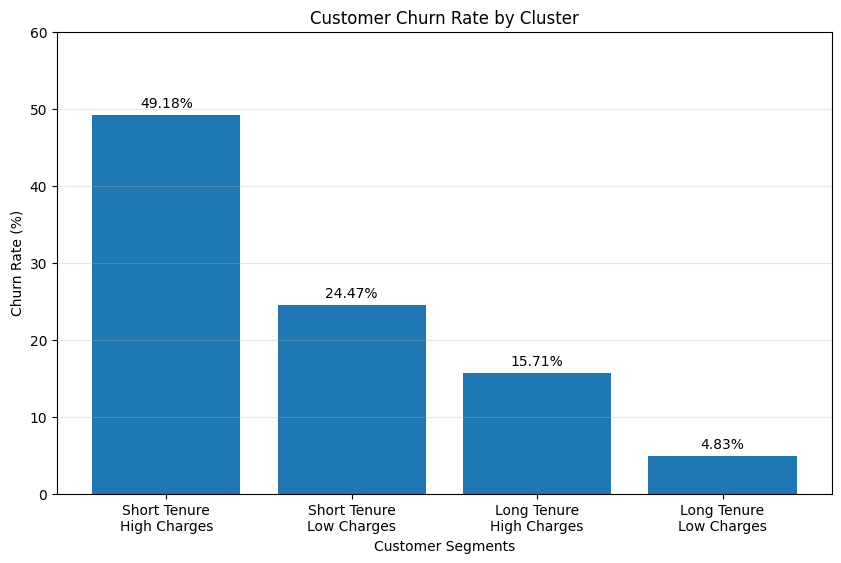

In [11]:

# Names of the four customer groups
cluster_labels = [
    "Short Tenure\nHigh Charges",
    "Short Tenure\nLow Charges",
    "Long Tenure\nHigh Charges",
    "Long Tenure\nLow Charges"
]

# Create the churn comparison graph
plt.figure(figsize=(10, 6))

bars = plt.bar(
    cluster_labels,
    churn_summary["Churn_Rate"]
)

# Show percentage above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.xlabel("Customer Segments")
plt.ylabel("Churn Rate (%)")
plt.title("Customer Churn Rate by Cluster")
plt.ylim(0, 60)
plt.grid(axis="y", alpha=0.3)

# Save graph for ACS report
plt.savefig(
    "customer_churn_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


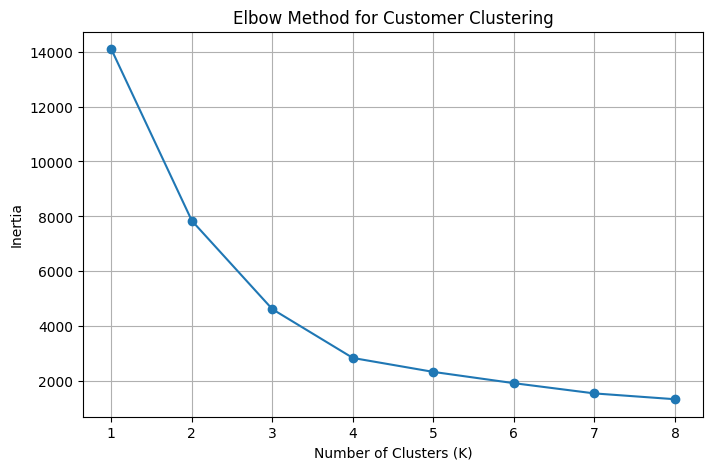

In [12]:

# Save the Elbow Method graph
plt.figure(figsize=(8, 5))

plt.plot(range(1, 9), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Clustering")
plt.grid(True)

plt.savefig(
    "elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:
import joblib
from google.colab import files

joblib.dump(kmeans, "kmeans_model.joblib")
files.download("kmeans_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>